# Analysis of the 2nd run of Chemeleon experiments

In [45]:
import pandas as pd
import numpy as np
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

runs_csv = "results/chemeleon/all_runs2.csv"
per_target_csv= "results/chemeleon/per_target2.csv"

HP = ["freeze_encoder", "encoder_lr", "head_lr", "readout", "hidden_dim", "num_layers",
      "dropout", "epochs","batch_size", "weight_decay", "grad_clip", "head_only_epochs",
      "reduce_lr", "lr_factor", "lr_patience"]

LOWER_IS_BETTER = {"regression": True, "classification": False}

df = pd.read_csv(runs_csv)
pt = pd.read_csv(per_target_csv)
df[HP] = df[HP].astype(object).where(df[HP].notna(), "NA")

print(f"Loaded: {df.shape[0]} runs, {df.shape[1]} columns\n")

Loaded: 78 runs, 26 columns



In [3]:
df.head(3)

,task,exp,seed,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,num_layers,dropout,epochs,batch_size,weight_decay,grad_clip,head_only_epochs,reduce_lr,lr_factor,lr_patience,val_score,baseline_score,best_epoch,epochs_run,final_score,train_loss_first,train_loss_last,overrides
0,classification,r2/01_frozen_linear,42,True,0.00001,0.001,linear,NA,NA,NA,20,32,0.0,1.0,0,False,0.5,2,0.149956,0.0,20,20,0.149956,0.533532,0.428361,model=chemeleon task=classification readout=li...
1,classification,r2/01_frozen_linear,43,True,0.00001,0.001,linear,NA,NA,NA,20,32,0.0,1.0,0,False,0.5,2,0.147442,0.0,19,20,0.103199,0.534993,0.427529,model=chemeleon task=classification readout=li...
2,classification,r2/01_frozen_linear,44,True,0.00001,0.001,linear,NA,NA,NA,20,32,0.0,1.0,0,False,0.5,2,0.143572,0.0,19,20,0.139214,0.529988,0.427227,model=chemeleon task=classification readout=li...


One exp value = one configuration (so each exp has 3 rows - for 3 seeds)

## Overall experiments statistics

In [4]:
scale = df.groupby("task").agg(
    n_run=("val_score", "size"), n_config=("exp", "nunique"),
    n_seed=("seed", "nunique"), val_min=("val_score", "min"),
    val_max=("val_score", "max"), val_mean=("val_score", "mean"),
    baseline=("baseline_score", "mean"),
).round(4)
print(scale)

                n_run  n_config  n_seed  val_min  val_max  val_mean  baseline
task                                                                         
classification     39        13       3   0.1436   0.3148    0.2642     0.000
regression         39        13       3   0.7038   0.7509    0.7275     0.983


39 runs both for regression and classification with 13 different hyperparameters/configurations. 
For classification min and max score differ substantilly while for regression they remain similar, suggesting that configurations did not matter that much. 

For both tasks Chemeleon managed to perform better than a naive predictor. 

#### Examine the differences between the results

From the table above we see that (especially for regression) the best and wost score dont differ that much. We want to test if changing the Hyperparameter configuration has a significant impact on the results. 

We use one way ANOVA test separately for each task treating the configuration as a grouping factor and seeds as replicates.  H0 being that U1 = U2 = ... = U13 where Ui is the expected value of the performance metric for config i taken over the random seeds.

(We are aware that 3 seeds per configuration provide limited statistical power)

In [7]:
for task, d in df.groupby("task"):
    g = d.groupby("exp").val_score.agg(["mean", "std"]).round(4)
    print("-----------------------")
    print(task)
    print(g.sort_values("mean").to_string())

-----------------------
classification
                              mean     std
exp                                       
r2/01_frozen_linear         0.1470  0.0032
r2/03_warmup_lr1e-5_linear  0.2188  0.0237
r2/02_unfrozen_linear       0.2441  0.0185
r2/03_warmup_lr1e-5_mlp     0.2721  0.0163
r2/05_wd1e-4_mlp            0.2745  0.0197
r2/01_frozen_mlp            0.2773  0.0099
r2/03_warmup_lr1e-4_linear  0.2783  0.0170
r2/06_reduce_lr_mlp         0.2807  0.0117
r2/03_warmup_lr1e-4_mlp     0.2837  0.0057
r2/04_dropout03_mlp         0.2876  0.0272
r2/05_wd1e-2_mlp            0.2877  0.0089
r2/02_unfrozen_mlp          0.2906  0.0267
r2/04_dropout01_mlp         0.2918  0.0070
-----------------------
regression
                              mean     std
exp                                       
r2/04_dropout03_mlp         0.7185  0.0042
r2/02_unfrozen_mlp          0.7204  0.0179
r2/05_wd1e-2_mlp            0.7215  0.0190
r2/04_dropout01_mlp         0.7237  0.0195
r2/05_wd1e-4_mlp       

In [15]:
from scipy import stats

regression_tasks = df[df['task']=='regression']
classif_tasks = df[df['task']=='classification']

val_scores =[]
for exp in regression_tasks['exp'].unique():
    val_scores.append(regression_tasks[regression_tasks['exp']==exp]['val_score'])
reg_test = stats.f_oneway(*val_scores)
print(" Regression ANOVA p val : ", round(reg_test.pvalue,5))

val_scores2 =[]
for exp in classif_tasks['exp'].unique():
    val_scores2.append(classif_tasks[classif_tasks['exp']==exp]['val_score'])
cls_test = stats.f_oneway(*val_scores2)
print("Classification ANOVA p val : ", round(cls_test.pvalue,5))




 Regression ANOVA p val :  0.80119
Classification ANOVA p val :  0.0


p value = 0.8 for regression suggests that there is no proof of significant difference between condigurations. 

However p value = 0 for classifcation is a sign that for this task choosing a different configuration can significantly improve the performance.

## Best runs vs best configurations:

#### Best single runs

In [16]:
df_regression = df[df['task']=='regression']
best_config_reg = df_regression[df_regression['val_score'] == df_regression['val_score'].min()]

print("Regression best score : ", df_regression['val_score'].min())
print("Winning config : -----------------------------------------")

best_config_reg[['freeze_encoder', 'encoder_lr', 'head_lr', 'readout', 'hidden_dim', 'dropout', 'weight_decay','head_only_epochs']]

Regression best score :  0.7037734068569841
Winning config : -----------------------------------------


,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,dropout,weight_decay,head_only_epochs
48,False,0.00001,0.001,mlp,512.0,0.0,0.0,0


In [17]:
df_classification = df[df['task']=='classification']
best_config_cls = df_classification[df_classification['val_score'] == df_classification['val_score'].max()]

print("Classif best score : ", df_classification['val_score'].max())
print("Winning config : -----------------------------------------")

best_config_cls[['freeze_encoder', 'encoder_lr', 'head_lr', 'readout', 'hidden_dim', 'dropout', 'weight_decay', 'head_only_epochs']]

Classif best score :  0.3148326841405417
Winning config : -----------------------------------------


,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,dropout,weight_decay,head_only_epochs
11,False,0.00001,0.001,mlp,512.0,0.0,0.0,0


The best run for both tasks is the one for configuration with end to end finetuning, MLP head with 512 neurons, and no dropout and no weight decay

### Best configuration (over all seeds)

In [18]:
for task, d in df.groupby("task"):
    stats = d.groupby("exp").val_score.agg(["mean"])
    best = stats["mean"].idxmin() if task == "regression" else stats["mean"].idxmax()
    print(f"{task}: {best} = {stats.loc[best,'mean']:.4f}")
    print(d[d.exp == best].iloc[0][["readout", "dropout", "hidden_dim","freeze_encoder", "encoder_lr","head_lr","head_only_epochs"]].to_string())

classification: r2/04_dropout01_mlp = 0.2918
readout                mlp
dropout                0.1
hidden_dim           512.0
freeze_encoder       False
encoder_lr          0.0001
head_lr              0.001
head_only_epochs         5
regression: r2/04_dropout03_mlp = 0.7185
readout                mlp
dropout                0.3
hidden_dim           512.0
freeze_encoder       False
encoder_lr          0.0001
head_lr              0.001
head_only_epochs         5


When analyzing the whole configurations instead of a single run the results are a little different between tasks. 

Both configurations are warmups instead of end to end finetuning with MLP head 512 neurns but with a larger encoder lr = 0.0001 and differences in dropout. 

### Improvement relative to the naive predictor:

In [19]:
for task, d in df.groupby("task"):
    lower = task == "regression"
    g = d.groupby("exp").val_score.agg(["mean", "std"])
    best = g["mean"].idxmin() if lower else g["mean"].idxmax()
    m, b = g.loc[best, "mean"], d.baseline_score.iloc[0]

    print("---------------------------")
    print(f"{task} : baseline = {b:.4f}")
    print(f"   best config: {best} = {m:.4f}")
    print(f"   absolute improvement from naive baseline = {(b - m) if lower else (m - b):.4f}")
    print(f"   relative improvement from naive baseline = {100*(b - m)/b:.1f}%" if b else
          "   relative improvement: - (baseline = 0)")

---------------------------
classification : baseline = 0.0000
   best config: r2/04_dropout01_mlp = 0.2918
   absolute improvement from naive baseline = 0.2918
   relative improvement: - (baseline = 0)
---------------------------
regression : baseline = 0.9830
   best config: r2/04_dropout03_mlp = 0.7185
   absolute improvement from naive baseline = 0.2646
   relative improvement from naive baseline = 26.9%


We managed to get some improvement compared to the naive models. (Next step : compare with other baselines and Atom Jepa)

## Configurations analysis

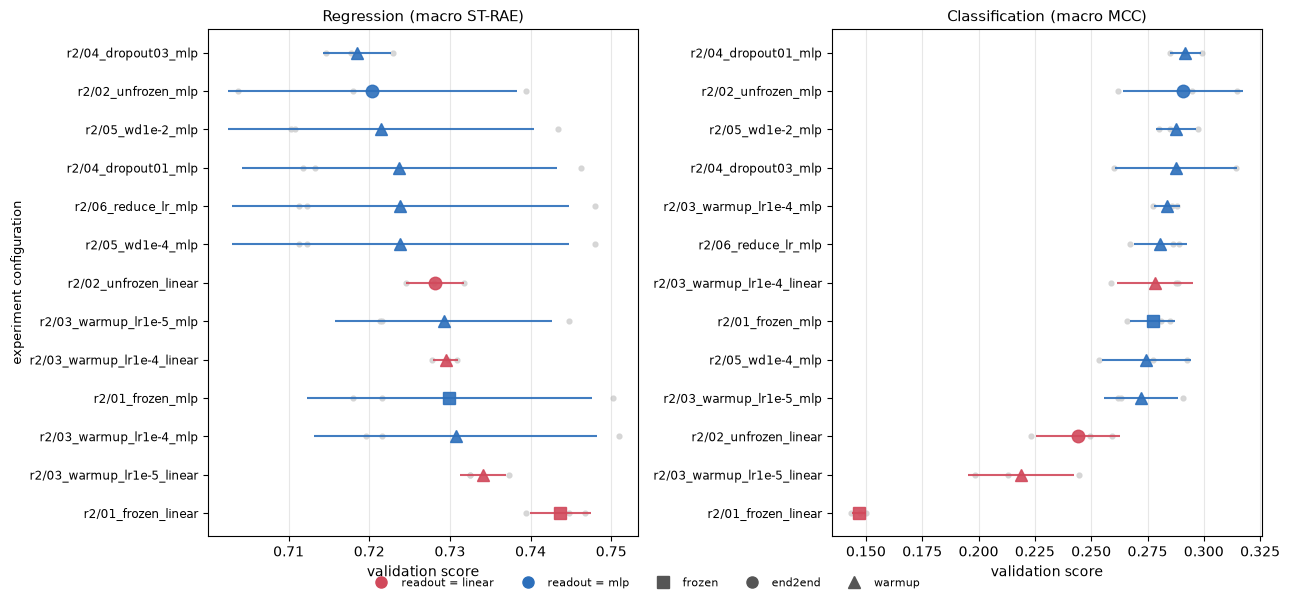

In [29]:
def add_method(row):
    if row['freeze_encoder']==True:
        return "frozen"
    elif row['head_only_epochs']>0:
        return "warmup"
    else:
        return "end2end"

df['method'] = df.apply(add_method, axis =1)

colors = {"linear": "#d1495b", "mlp": "#2c6fbb"}
markers = {"frozen": "s", "end2end": "o", "warmup": "^"}
titles = {"regression": "Regression (macro ST-RAE)",
          "classification": "Classification (macro MCC)"}

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, task in zip(axes, ["regression", "classification"]):
    task_df = df[df["task"] == task]

    summary_grouped = task_df.groupby(["exp", "readout", "method"])["val_score"].agg(["mean", "std"])
    summary_grouped = summary_grouped.reset_index()
  
    summary_grouped = summary_grouped.sort_values("mean", ascending=(task == "regression"))
    summary_grouped = summary_grouped.reset_index(drop=True)

    for i, row in summary_grouped.iterrows():
        color = colors[row["readout"]]
        ax.errorbar(row["mean"], i, xerr=row["std"], fmt=markers[row["method"]],
                    color=color, alpha=0.9, markersize=9)

        single_runs = task_df[task_df["exp"] == row["exp"]]["val_score"]
        ax.scatter(single_runs, [i] * len(single_runs), s=12, color="lightgray", alpha=0.9)

    ax.set_yticks(range(len(summary_grouped)))
    ax.set_yticklabels(summary_grouped["exp"], fontsize=8.5)
    ax.invert_yaxis()
    ax.set_title(titles[task], fontsize=11)
    ax.set_xlabel("validation score")
    ax.grid(axis="x", alpha=0.3)

axes[0].set_ylabel("experiment configuration", fontsize=9)

for name, color in colors.items():
    axes[0].plot([], [], "o", color=color, ms=8, label=f"readout = {name}")
for name, marker in markers.items():
    axes[0].plot([], [], marker, color="#555", ms=8, label=name)

fig.legend(loc="lower center", ncol=5, fontsize=8, frameon=False)


plt.tight_layout()
fig.savefig("figures/results_per_config.pdf", bbox_inches="tight")
plt.show()


Conclusions about parameter configurations:

1) MLP readout is the finning head for both tasks ( top 6 configurations are with MLP head)

2) end to end finetuning and warmup perform better than frozen weights 

3) For regression the best 3 configurations differ in encoder Lr, dropout and weight decay, the worst 2 configurations are linear heads with warmup and frozen - what is interesting linear head but with end to end finetuning is above some configurations with MLP readouts with frozen/warmups.

4) For classification the 3 best configurations also differ in parameters but are all MLP readout with end to end or warmup. The 3 worst configurations are 3 out of 4 fine tuning methods for linear.

#### Does unfreezing the encoder help?

In [30]:
# no dropout, weight decay and scheduler
base = df[(df['dropout']=='NA') | (df['dropout']==0)].copy()
base = base[base['weight_decay']== 0]
base = base[base['reduce_lr']==False]

tab = (base.pivot_table(index=["task", "readout"], columns="method",
                        values="val_score", aggfunc="mean")
           .round(4))
print(tab.to_string())

method                  end2end  frozen  warmup
task           readout                         
classification linear    0.2441  0.1470  0.2486
               mlp       0.2906  0.2773  0.2779
regression     linear    0.7281  0.7437  0.7318
               mlp       0.7204  0.7299  0.7300


Unfreezing the encoder helps for both tasks with linear head. For MLP head however, the results remain very similar regardless of e2e tuning or using the freezed weights.

Conclusion : non linear head can alone extract the information it needs, while linear head benefits from finetuning the encoder. This suggests that the pretraied chemeleon already has the necessary information encoded but not in a linearly separable form, then non linear MLP head substitutes for encoder adaptation and not substitutes it.

## Best epoch analysis 

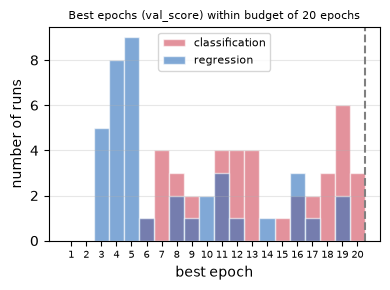

In [40]:
COLOR  = {"regression": "#2c6fbb", "classification": "#d1495b"}
budget = 20 #this is max epochs in every experiment
bins = np.arange(0.5, budget + 1.5)      
fig, ax = plt.subplots(figsize=(4, 3))
for task, d in df.groupby("task"):
    ax.hist(d.best_epoch, bins=bins, alpha=0.6,
            label=task, color=COLOR[task], edgecolor="white")
ax.axvline(budget + .5, ls="--", color='gray')
ax.set_xticks(range(1, budget + 1))
ax.tick_params(axis="x", labelsize=7)
ax.set_xlabel("best epoch")
ax.set_ylabel("number of runs")
ax.set_title("Best epochs (val_score) within budget of 20 epochs", fontsize=8)
ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout()
fig.savefig("figures/best_epochs.pdf", bbox_inches="tight")

plt.show()

We see that most regression runs needed only a few epochs to reach their ceeling score - then they just started to overfit. For classification the number of epochs needed to reach the best score is more distributed between 6 and 20 epochs. For some runs the best epoch was the last one (suggesting that maybe with a longer training we could obtain better results ? lets check the epoch for winning config)

In [37]:
d = df[df.task == "classification"]
best = d.groupby("exp").val_score.mean().idxmax()
print(d[d.exp == best][["exp", "seed", "best_epoch", "val_score"]].to_string(index=False))

                exp  seed  best_epoch  val_score
r2/04_dropout01_mlp    42          13   0.299029
r2/04_dropout01_mlp    43          13   0.291260
r2/04_dropout01_mlp    44          11   0.285123


The best results we have for classification were obtained in epoch 13.

**important conclusion** : The best config for classification is FOR THIS BUDGET of 20 epochs (not necessarily overall because we dont know which results we would get after running it longer)

# Per target performance analysis

See how the per target validation score depends on the number of training samples in this class

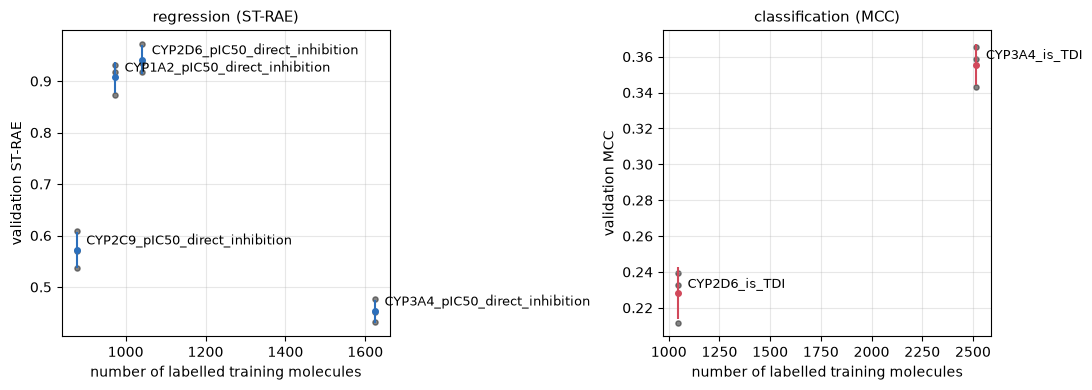

In [41]:
from pathlib import Path
DATA = Path("../data")          

#count train examples for each target and each task
n_train = {}
for task in ["regression", "classification"]:
    train_df = pd.read_csv(DATA / task / "train.csv")
    targets = pt.loc[pt.task == task, "target"].unique()
    n_train[task] = train_df[list(targets)].notna().sum()

BEST   = {"regression": "r2/04_dropout03_mlp", "classification": "r2/04_dropout01_mlp"}
METRIC = {"regression": "ST-RAE", "classification": "MCC"}
COLOR  = {"regression": "#2c6fbb", "classification": "#d1495b"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, task in zip(axes, ["regression", "classification"]):
    m = METRIC[task]
    d = pt[(pt.task == task) & (pt.exp == BEST[task])]
    g = d.groupby("target").agg(mean=(m, "mean"), std=(m, "std"))
    g["n_train"] = g.index.map(n_train[task])

    ax.errorbar(g["n_train"], g["mean"], yerr=g["std"], fmt="o", color=COLOR[task],
                ecolor=COLOR[task], markersize=4)
    ax.scatter(d.target.map(n_train[task]), d[m], s=14, color="#333", alpha=0.6)
    for t, r in g.iterrows():
        ax.annotate(t, (r["n_train"], r["mean"]), textcoords="offset points",
                    xytext=(7, 4), fontsize=9)

    ax.set_xlabel("number of labelled training molecules")
    ax.set_ylabel(f"validation {m}")
    ax.set_title(f"{task} ({m})", fontsize=11)
    ax.grid(alpha=.3)
 

plt.tight_layout()
fig.savefig("figures/score_vs_n_train.pdf", bbox_inches="tight")

plt.show()

In [89]:
d = pt[(pt.task == "regression") & (pt.exp == BEST["regression"])]
print(d.groupby("target")[["MAE", "R2", "ST-RAE"]].mean().round(3).to_string())

                                  MAE     R2  ST-RAE
target                                              
CYP1A2_pIC50_direct_inhibition  0.752  0.121   0.908
CYP2C9_pIC50_direct_inhibition  0.488  0.443   0.572
CYP2D6_pIC50_direct_inhibition  0.643  0.130   0.941
CYP3A4_pIC50_direct_inhibition  0.550  0.560   0.453


For classification the hypothesis about an impact of the number of training samples on the score can be somehow supported by the plot - CYP2D6 has around 3 times lower amount of training samples and also the MCC is much lower. However for regression this hypothesis is not confirmed - CYP2C9 although having the least amount of training data has a better score than CYP2D6 and CYP1A2. This can suggest that the difficulty lies in the targets themselves (not in the construction of the dataset)

# Test performance on the architecture chosen by the best validation scores

In [43]:
import json

regression_test_path = Path("results/chemeleon/test_metrics_regression_run2.json")
classif_test_path = Path("results/chemeleon/test_metrics_classification_run2.json")

reg_test_results = json.loads(regression_test_path.read_text())
reg_test_results["macro"] = reg_test_results.pop("macro_ST-RAE")

cls_test_results = json.loads(classif_test_path.read_text())
cls_test_results["macro"] = cls_test_results.pop("macro_MCC")

reg_test_results

{'CYP1A2_pIC50_direct_inhibition': {'MAE': 0.6346178939843484,
  'R2': 0.2466865710413363,
  'ST-RAE': 0.8436128079518462,
  'n': 229},
 'CYP2C9_pIC50_direct_inhibition': {'MAE': 0.46593734911940377,
  'R2': 0.31993713801359447,
  'ST-RAE': 0.725183193082832,
  'n': 199},
 'CYP2D6_pIC50_direct_inhibition': {'MAE': 0.6205199787520669,
  'R2': 0.1489364780074165,
  'ST-RAE': 0.9625119538785859,
  'n': 222},
 'CYP3A4_pIC50_direct_inhibition': {'MAE': 0.5527514978353614,
  'R2': 0.5622500963546149,
  'ST-RAE': 0.4938519626305669,
  'n': 374},
 'macro': 0.7562899793859578}

Overall macro scores worse on test sets. For classification the difference is more visible.

Plot the differences per target :

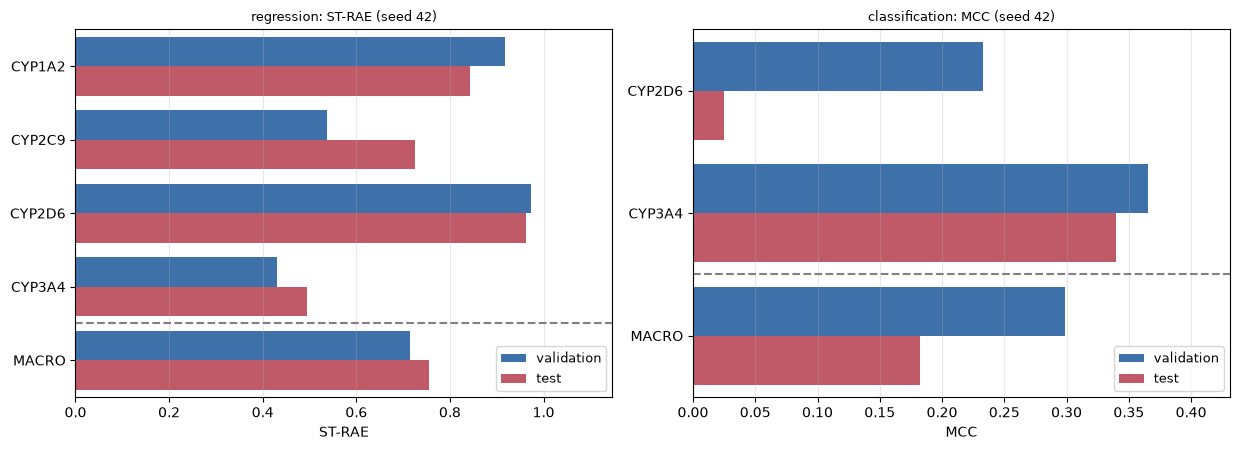

In [49]:
COLORS = {"validation": "#2c6fbb", "test": "#d1495b"}
def plot_task(ax, task, exp, metric, test_results):
    val = pt[(pt["task"] == task) & (pt["exp"] == exp) & (pt["seed"] == 42)] #comparing only on seed 42 bc testing was only on seed 42 and not all 3 seeds
    val = val.set_index("target")[metric]

    rows = []
    for target, score in val.items():
        rows.append({"target": target, "split": "validation", "score": score})
        rows.append({"target": target, "split": "test", "score": test_results.get(target, {}).get(metric)})
    
    rows.append({"target": "MACRO", "split": "validation", "score": val.mean()})
    rows.append({"target": "MACRO", "split": "test", "score": test_results["macro"]})

    data = pd.DataFrame(rows)
    data["target"] = data["target"].str.replace("_pIC50_direct_inhibition", "").str.replace("_is_TDI", "")

    sns.barplot(data=data, x="score", y="target", hue="split", ax=ax, palette=COLORS)

    ax.axhline(len(val) - 0.5, color="gray", ls="--")  # separate row for Macro res comparison
    ax.set_title(f"{task}: {metric} (seed 42)", fontsize=9)
    ax.set_xlabel(metric)
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)
    ax.legend(fontsize=9, loc="lower right")
    ax.margins(x=0.18)


fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
plot_task(axes[0], "regression", "r2/04_dropout03_mlp", "ST-RAE", reg_test_results)
plot_task(axes[1], "classification", "r2/04_dropout01_mlp", "MCC", cls_test_results)

plt.tight_layout()
fig.savefig("figures/val_vs_test.pdf", bbox_inches="tight")
plt.show()

**Conclusions**:

For regression 2 targets are better on validation and 2 targets are better on test.  Overall Macro score is best for validation. The biggest difference between test and valid is for CYP2C9 with test score being significantly worse than validations core. However, this is stil one of 2 targets with the best results. The wors validation and test scores are observed for CYP2D6 (the problematic one) and CYP1A2. 

For classification Macro score is significantly lower on test due to the rapid decrease of MCC for CYP2D6 on test set. 

# Final notes:

### Hyperparameters barely matter

across 13 configs and 3 seeds, one way anova did not find a significant effect of configuration on the validation performence for regression. The gap between best and worst score is no larger than seed to seed fluctuations. 

For classification the impact is real but mostly comes from frozen linear setup vs the rest. 

The main differences were caused by the choice of finetuning stratey and head architecture, while adding dropout, weight decay, different learning rates did not have a major impact.

### The only factor that matters is the readout — and only when the encoder is frozen
|task | frozen | e2e | warmup 1e-5 | warmup 1e-4 |
|---|---|---|---|---|
| classification, linear | 0.1470 | 0.2441 | 0.2188 | 0.2783 |
| classification, mlp | 0.2773 | 0.2906 | 0.2721 | 0.2837 |
| regression, linear | 0.7437 | 0.7281 | 0.7341 | 0.7295 |
| regression, mlp | 0.7299 | 0.7204 | 0.7292 | 0.7307 |

Unfreezing the encoder does substantially help with linear head but does not improve performance with MLP head. An explanation of this could be that chemeleon pretrained model already contains the necessary information but encoded in a non linearly separable way - therefore linear model can benefit from encoder training and the MLP head acts as a substitue for this : MLP + end to end finetuning does not improve the results.

### Absolute performance on validation is fine but not ideal

We managed to get some improvement regarding the naive baseline model, however the difference is not large and decreases even more on test. After examination of the separate targets we find quite big differences between their performance suggesting that some of them are easier to learn than others. 

Sample count explains some problems for classification where the class with the lower number of samples got substantially lower scores, but this class CYP2D6 turns out to be problematic for both tasks - this is an indicator that this particular endpoint can be hard for the model.

TEST SCORES : transfers well for regression, in classification even bigger problem with CYP2D6 occur during inference.  The entire macro decline from 0.288 to 0.182 comes
from this single endpoint.

### Best run vs best config 

Best run configuration does not necessarily match the best config when inspecting the impact of different seeds. 


